# P1: does heat predict luna moths better than the calendar?

**The bet.** Each luna moth is a bank account that fills with warm days ("degree-days"). When the balance
crosses its threshold, it flies. If that is true, a warm spring should bring lunas early and a cold one late,
and a heat forecast should beat "same date as usual".

**The test (build-plan-v2, P1).** Before trusting a scale to weigh gold, weigh a known 1 kg block on it:
1. freeze the choices first ([FROZEN_CHOICES.md](FROZEN_CHOICES.md)),
2. census the data, 3. plot the wave, 4. simulate-and-recover,
5. score baselines leave-one-year-out on **dates**, 6. read off which headline is earned.

Fireflies (*Photinus pyralis*) go through the same pipe as an outside check against a published rule.
Data: iNaturalist (7 Midwest states), Daymet v4 daily temperatures at H3 res-4 hex centres, 2015-2025.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from hatch_p1.run import load, temps, index, BASES, DATA
from hatch_p1 import model
from hatch_p1.census import census
from hatch_p1.simulate import effort_matrix, recover
from hatch_p1.inat import fetch_taxon, fetch_daily_effort
pd.set_option('display.precision', 1)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
MOON, GREY, EMBER = '#4c9a6a', '#9aa0a6', '#c8743a'

# downloads are cached in data/ (gitignored); first run takes ~15 min
luna_raw = fetch_taxon(47916, DATA / 'luna_inat.parquet')
fly_raw = fetch_taxon(129350, DATA / 'pyralis_inat.parquet')
effort = fetch_daily_effort(47157, 47224, range(2008, 2026), DATA / 'moth_effort.parquet')

## 2. Census
How much data, how clustered, how late. (Review 2 predicted ~9.6% of luna records uploaded >1 year late,
one observer dominating the top hex, and a low firefly research-grade share.)

In [2]:
pd.DataFrame({'luna': census(luna_raw), 'firefly': census(fly_raw)}).map(lambda v: f'{v:.1%}' if v < 1 else f'{v:,.0f}')

,luna,firefly
all records (7 states),"6,809","10,918"
research grade share,97.6%,35.4%
needs-ID share,0.1%,63.8%
captive share,0.9%,0.0%
obscured share,7.3%,15.3%
annotated adult share,77.5%,45.8%
annotated non-adult share,10.3%,0.8%
no life-stage annotation share,12.2%,53.4%
uploaded >30 days late,18.6%,6.0%
uploaded >1 year late,9.8%,2.0%


In [3]:
rec_all, _ = load('luna_inat.parquet', split_broods=False)
pd.crosstab(rec_all.year, rec_all.band, margins=True)

band,37-39,39-41,41-43,43-45,45-49,All
year,,,,,,
2015,13,29,30,5,4,81
2016,11,38,20,6,7,82
2017,17,29,20,9,12,87
2018,13,43,39,13,12,120
2019,38,131,112,32,31,344
2020,32,134,115,19,42,342
2021,56,178,97,7,69,407
2022,51,125,85,12,85,358
2023,54,177,116,26,75,448


## 3. The wave
Day of year against latitude, all years pooled. If heat drives first flight, the spring brood should slide later
going north. Grey = records the frozen brood rule calls **second brood** (southern summer generation, set by daylength, shown as observed in v1).

brood cut-offs (day of year): {'37-39': 177, '39-41': 180, '41-43': 176, '43-45': 190, '45-49': None}
first-brood median day by band: {'37-39': 136.0, '39-41': 142.0, '41-43': 148.0, '43-45': 158.0, '45-49': 172.0}


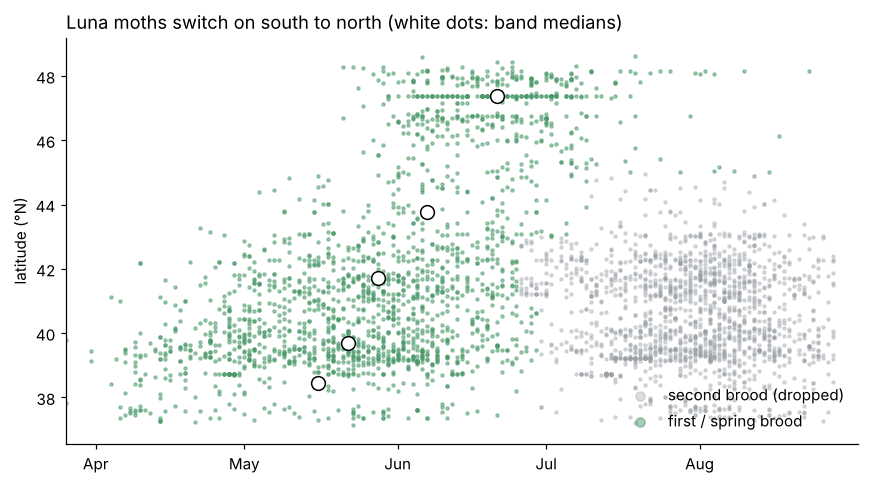

In [4]:
rec, cut = load('luna_inat.parquet')
print('brood cut-offs (day of year):', cut)
second = rec_all[~rec_all.id.isin(rec.id)]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(second.doy, second.lat, s=4, c=GREY, alpha=.35, label='second brood (dropped)')
ax.scatter(rec.doy, rec.lat, s=4, c=MOON, alpha=.5, label='first / spring brood')
for b, g in rec.groupby('band', observed=True):
    ax.plot(g.doy.median(), g.lat.median(), 'o', ms=9, mfc='white', mec='k')
months = pd.to_datetime(['2025-04-01','2025-05-01','2025-06-01','2025-07-01','2025-08-01']).dayofyear
ax.set_xticks(months, ['Apr', 'May', 'Jun', 'Jul', 'Aug'])
ax.set_xlim(85, 245); ax.set_ylabel('latitude (°N)')
ax.set_title('Luna moths switch on south to north (white dots: band medians)', loc='left')
ax.legend(loc='lower right', frameon=False, markerscale=3)
fig.tight_layout(); fig.savefig('figures/wave.png', dpi=150)
first = rec.groupby('band', observed=True).doy.median()
print('first-brood median day by band:', first.to_dict())

## 4. Temperatures and degree-days
Double-sine, base 10 °C, upper cutoff 30 °C, from 1 March. Tests in `hatch_p1/test_degree_days.py` check the closed form
against brute-force integration of the sine.

In [5]:
hexes, years, tmin, tmax = temps(rec)
r = index(rec, hexes, years)
cubes = {float(b): model.dd_cube(tmin, tmax, b) for b in BASES}
dd10 = cubes[10.0]
r['dd10'] = model.dd_at_sightings(r, dd10)
print(f'{len(hexes)} hexes, {len(r)} first-brood records')
r.groupby('band').dd10.describe(percentiles=[.1, .5, .9])[['count', '10%', '50%', '90%']]

363 hexes, 2023 first-brood records


,count,10%,50%,90%
band,,,,
37-39,220.0,128.9,322.3,584.6
39-41,722.0,126.1,300.1,535.4
41-43,443.0,125.7,260.5,463.1
43-45,147.0,135.4,258.1,508.1
45-49,491.0,134.4,234.0,375.1


**Read this table like a receipt.** Median "warmth saved up" at a sighting is 230-320 degree-days in every band,
even though the calendar dates are a month apart. That is the bank-account idea holding roughly. Note the long right
tail (90th percentile ≈ 2× the median): a symmetric bell curve in degree-days will not fit it well.

## 5. Baselines, leave-one-year-out, scored on dates
Targets per band-year (≥ 20 records): **onset** = 10th percentile day, **peak** = median day.
The noise floor is how precisely the target itself is known (bootstrap SD).

In [6]:
tg = model.noise_floor(r, model.targets(r))
print('scored band-years:', len(tg), '| with 150+ records:', (tg.n >= 150).sum())
print('noise floor (median bootstrap SD, days):', tg[['sd_onset', 'sd_peak']].median().round(1).to_dict())
a = model.calendar_predictions(tg)
c = model.heat_predictions(r, tg, dd10, years)
d = model.full_predictions(r, tg, cubes, years)
table = pd.DataFrame({k: model.score(tg, p) for k, p in
                      {'(a) calendar': a, '(c) heat, base 10 °C': c, '(d) heat, base learned': d}.items()}).T
print('learned base per held-out year:', d.groupby('year').base.first().to_dict())
table

scored band-years: 31 | with 150+ records: 1
noise floor (median bootstrap SD, days): {'sd_onset': 3.1, 'sd_peak': 3.5}


learned base per held-out year: {2016: 0.0, 2018: 0.0, 2019: 0.0, 2020: 0.0, 2021: 0.0, 2022: 0.0, 2023: 0.0, 2024: 0.0, 2025: 0.0}


,n_band_years,mae_onset,mae_peak,mae
(a) calendar,31.0,8.0,6.7,7.3
"(c) heat, base 10 °C",31.0,18.7,4.0,11.4
"(d) heat, base learned",31.0,8.5,4.1,6.3


In [7]:
for name, p in [('(c) vs (a)', c), ('(d) vs (a)', d)]:
    diff, ci = model.paired_bootstrap(tg, a, p)
    print(f'{name}: calendar MAE minus model MAE = {diff:+.1f} days (95% CI over years {ci[0]:+.1f} to {ci[1]:+.1f})')
diff, ci = model.paired_bootstrap(tg, c, d)
print(f'(d) vs (c): {diff:+.1f} days (95% CI {ci[0]:+.1f} to {ci[1]:+.1f})')

(c) vs (a): calendar MAE minus model MAE = -4.0 days (95% CI over years -7.3 to -1.0)
(d) vs (a): calendar MAE minus model MAE = +1.0 days (95% CI over years -1.2 to +3.1)
(d) vs (c): +5.1 days (95% CI +3.8 to +6.5)


**What happened.** Heat nails the **peak** (≈4 days off vs ≈7 for the calendar, not far above the noise floor)
but misses the **onset** by ~19 days, always too early. That is the bell curve: the real spread of degree-days at sightings is
skewed (long warm tail), so a symmetric curve puts its 10% point far too low. (d) "improves" by sliding the base to 0 °C, the
edge of the grid, which flattens the skew. That is the fitter compensating for the wrong curve, not learning biology.

## 6. Simulate-and-recover
Fake sightings from a known base (8, 10, 12 °C) using real temperatures, real places and counts, and real daily moth effort.
Can the (d) fitter find the base again? Pass = within ±1 °C.

In [8]:
eff = effort_matrix(effort, years)
# 'model exactly true': fake sightings follow the fitter's own curve. 'with effort': plus real day-to-day moth effort.
sim = pd.concat([recover(r, cubes, years, None, reps=20).assign(setup='model exactly true'),
                 recover(r, cubes, years, eff, reps=20, seed=1).assign(setup='with real effort')])
sim['within_1C'] = (sim.recovered - sim.true_base).abs() <= 1
sim.to_csv('figures/sim_recover.csv', index=False)
summary = sim.groupby(['setup', 'true_base']).agg(median=('recovered', 'median'), lo=('recovered', lambda x: x.quantile(.1)),
                                       hi=('recovered', lambda x: x.quantile(.9)), within_1C=('within_1C', 'mean'))
summary

median   lo    hi  within_1C
setup              true_base                              
model exactly true 8.0           6.0  2.5   8.1        0.2
                   10.0          7.0  3.7   8.1        0.1
                   12.0          9.0  4.4  11.1        0.2
with real effort   8.0           6.5  0.9  10.0        0.3
                   10.0          6.5  1.4   8.1        0.1
                   12.0         10.2  7.4  13.6        0.3

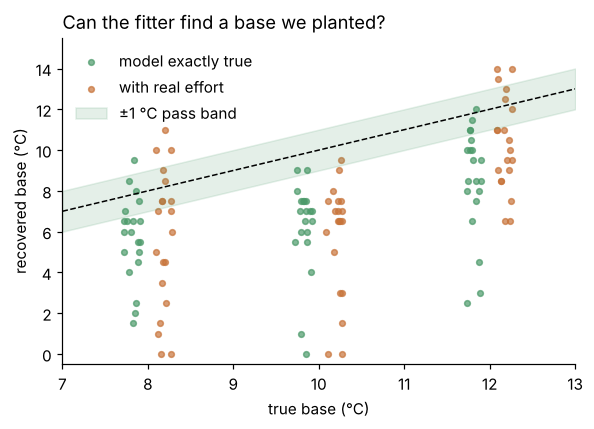

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4))
jit = np.random.default_rng(0)
for (setup, tb), g in sim.groupby(['setup', 'true_base']):
    off, col = (-.18, MOON) if setup == 'model exactly true' else (.18, EMBER)
    ax.scatter(np.full(len(g), tb + off) + jit.uniform(-.1, .1, len(g)), g.recovered, s=14, c=col, alpha=.7,
               label=setup if tb == 8.0 else None)
ax.plot([7, 13], [7, 13], c='k', lw=1, ls='--'); ax.fill_between([7, 13], [6, 12], [8, 14], color=MOON, alpha=.15, label='±1 °C pass band')
ax.set_xlabel('true base (°C)'); ax.set_ylabel('recovered base (°C)'); ax.set_xlim(7, 13); ax.set_ylim(-0.5, 15.5)
ax.set_title('Can the fitter find a base we planted?', loc='left'); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig('figures/sim_recover.png', dpi=150)

## 7. Firefly check against a published answer
Same pipe, *Photinus pyralis*, one brood. The published rule (800 DD, base 10 °C, double-sine from 1 March, peak)
is the one outside answer we can check the plumbing against.

In [10]:
frec, _ = load('pyralis_inat.parquet', split_broods=False)
fh, fy, ftmin, ftmax = temps(frec)
fr = index(frec, fh, fy)
fdd = model.dd_cube(ftmin, ftmax, 10)
ftg = model.noise_floor(fr, model.targets(fr))
fa, fc = model.calendar_predictions(ftg), model.heat_predictions(fr, ftg, fdd, fy)
rule = []
for _, x in ftg.iterrows():
    hx, w = model._band_weights(fr[fr.year != x.year], x.band)
    rule.append((x.band, x.year, np.nan, model.predict_rule(fdd, hx, w, int(x.year - fy[0]), 800)))
fb = pd.DataFrame(rule, columns=['band', 'year', 'onset_pred', 'peak_pred'])
m = ftg.merge(fb, on=['band', 'year'])
print(f'scored band-years: {len(ftg)}; median DD at sighting: {np.median(model.dd_at_sightings(fr, fdd)):.0f} (published peak: 800)')
print(f'(b) published rule, peak: MAE {(m.peak_pred - m.peak).abs().mean():.1f} d, bias {(m.peak_pred - m.peak).mean():+.1f} d (late)')
pd.DataFrame({'(a) calendar': model.score(ftg, fa), '(c) heat, base 10 °C': model.score(ftg, fc)}).T

scored band-years: 23; median DD at sighting: 716 (published peak: 800)
(b) published rule, peak: MAE 6.8 d, bias +6.5 d (late)


,n_band_years,mae_onset,mae_peak,mae
(a) calendar,23.0,4.9,5.8,5.4
"(c) heat, base 10 °C",23.0,5.4,4.0,4.7


## 8. Sensitivity and one exploratory check (not frozen; labelled as such)
* **Brood rule as originally frozen (50%)** instead of the logged change to 80%.
* **Skew-aware heat model.** Same as (c) but the bell curve is swapped for the actual spread of degree-days at
  training sightings. This is *not* a frozen baseline; it is the P3 item "compare a skewed curve", run early because
  section 5 pointed straight at it. Bases 10 °C and 5 °C, nothing else tried.

In [11]:
rec50, cut50 = load('luna_inat.parquet', frac=0.5)
e50 = model.empirical_predictions(r50 := index(rec50, hexes, years), tg50 := model.targets(r50), dd10, years)
d50, ci50 = model.paired_bootstrap(tg50, model.calendar_predictions(tg50), e50)
print(f'50% rule, skew-aware base 10 °C: {model.score(tg50, e50)["mae"]:.1f} d | vs calendar {d50:+.1f} d (95% CI {ci50[0]:+.1f} to {ci50[1]:+.1f})')
r50 = index(rec50, hexes, years); tg50 = model.targets(r50)
print('50% rule cut-offs:', cut50)
print('50% rule  (a):', {k: round(v, 1) for k, v in model.score(tg50, model.calendar_predictions(tg50)).items()})
print('50% rule  (c):', {k: round(v, 1) for k, v in model.score(tg50, model.heat_predictions(r50, tg50, dd10, years)).items()})
for base in (10.0, 5.0):
    e = model.empirical_predictions(r, tg, cubes[base], years)
    diff, ci = model.paired_bootstrap(tg, a, e)
    print(f'skew-aware, base {base:.0f} °C:', {k: round(v, 1) for k, v in model.score(tg, e).items()},
          f'| beats calendar by {diff:+.1f} d (95% CI {ci[0]:+.1f} to {ci[1]:+.1f})')
e10 = model.empirical_predictions(r, tg, dd10, years)

50% rule, skew-aware base 10 °C: 10.3 d | vs calendar -1.2 d (95% CI -4.1 to +1.7)
50% rule cut-offs: {'37-39': 177, '39-41': 180, '41-43': None, '43-45': None, '45-49': None}
50% rule  (a): {'n_band_years': 34, 'mae_onset': np.float64(7.9), 'mae_peak': np.float64(10.2), 'mae': np.float64(9.1)}
50% rule  (c): {'n_band_years': 34, 'mae_onset': np.float64(132.4), 'mae_peak': np.float64(14.8), 'mae': np.float64(73.6)}


skew-aware, base 10 °C: {'n_band_years': 31, 'mae_onset': np.float64(3.9), 'mae_peak': np.float64(4.2), 'mae': np.float64(4.0)} | beats calendar by +3.3 d (95% CI +0.9 to +5.4)
skew-aware, base 5 °C: {'n_band_years': 31, 'mae_onset': np.float64(3.8), 'mae_peak': np.float64(4.2), 'mae': np.float64(4.0)} | beats calendar by +3.3 d (95% CI +1.1 to +5.2)


With the 50% rule the 41-43 and 43-45 bands keep their July second brood, the bell curve widens until it puts ~15% of
moths before any warmth at all (onset predicted on 1 Jan), and the calendar's peak error also jumps to 10 days.
So the brood split matters more than any model choice; the 80% rule is the one used everywhere else.

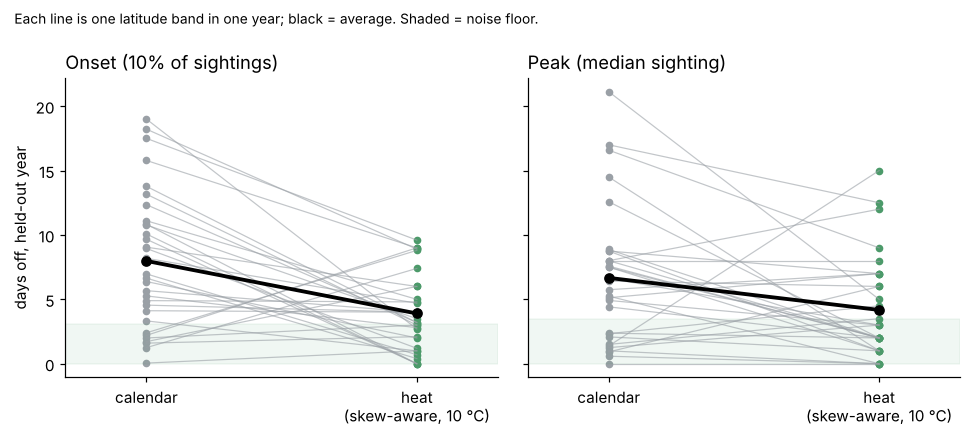

In [12]:
# one picture of the answer: per band-year peak error, calendar vs heat
mc = tg.merge(a, on=['band', 'year']).merge(e10, on=['band', 'year'], suffixes=('_cal', '_heat'))
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, k, title in [(axs[0], 'onset', 'Onset (10% of sightings)'), (axs[1], 'peak', 'Peak (median sighting)')]:
    err_cal, err_heat = (mc[f'{k}_pred_cal'] - mc[k]).abs(), (mc[f'{k}_pred_heat'] - mc[k]).abs()
    for i, (lo, hi) in enumerate(zip(err_cal, err_heat)):
        ax.plot([0, 1], [lo, hi], c=GREY, lw=.8, alpha=.6)
    ax.scatter(np.zeros(len(mc)), err_cal, c=GREY, s=16); ax.scatter(np.ones(len(mc)), err_heat, c=MOON, s=16)
    ax.plot([0, 1], [err_cal.mean(), err_heat.mean()], c='k', lw=2.5, marker='o')
    ax.axhspan(0, tg[f'sd_{k}'].median(), color=MOON, alpha=.08)
    ax.set_xticks([0, 1], ['calendar', 'heat\n(skew-aware, 10 °C)']); ax.set_xlim(-.3, 1.3); ax.set_title(title, loc='left')
axs[0].set_ylabel('days off, held-out year'); fig.suptitle('Each line is one latitude band in one year; black = average. Shaded = noise floor.', x=.02, ha='left', fontsize=9)
fig.tight_layout(); fig.savefig('figures/calendar_vs_heat.png', dpi=150)

## 9. Verdict
See [RESULT.md](RESULT.md) for the one-page reading of these numbers against the go/no-go table.